# Construction Cost Analysis and Prediction

Estimate final package cost from the planned budget and complexity. Use this as an estimator-review demonstration.

**Beginner/intermediate learning project. Synthetic data only. AI-assisted implementation.**
Учебный проект начального/среднего уровня, созданный с помощью AI. Данные синтетические.

Run this notebook from its project folder. Read the short Python cells in order; the CSV and generator are included.


## 1. Read the historical examples
Load one independent record per fictional work package. / Одна строка — отдельный учебный проект.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("data/synthetic_data.csv")
print(df.head().to_string(index=False))

 project_id  work_type  quantity_m3  unit_price_usd  complexity  actual_cost_usd
          1   Rockfill          131              32           4          8104.62
          2   Rockfill         1147              32           4         47898.15
          3   Concrete          307             110           4         45263.40
          4 Excavation          802              18           4         22445.39
          5   Concrete         1405             110           1        162076.48


## 2. Calculate costs with Pandas
Multiply volume by unit price, calculate the historical overrun and group totals. / Считаем плановую стоимость, перерасход и суммы по видам работ. Overrun is retrospective analysis, not a model input.


In [2]:
df["planned_cost"] = df["quantity_m3"] * df["unit_price_usd"]
df["overrun"] = df["actual_cost_usd"] - df["planned_cost"]
df["overrun_percent"] = df["overrun"] / df["planned_cost"] * 100
summary = df.groupby("work_type")[["planned_cost", "actual_cost_usd"]].sum()
print(summary.round(2).to_string())
print("Packages above budget:", len(df[df["overrun"] > 0]))

            planned_cost  actual_cost_usd
work_type                                
Concrete         4128300       4462805.85
Excavation        714168       1000144.60
Rockfill          880896       1114524.90
Packages above budget: 114


## 3. Keep some projects for the final check
X contains planned budget and complexity; y is the final cost. / X — известные до начала работ признаки, y — итоговая стоимость. Hold out 25% of independent projects.


In [3]:
# Only planned information is used as input, never actual cost or overrun.
X = df[["planned_cost", "complexity"]]
y = df["actual_cost_usd"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Training:", len(X_train), "Testing:", len(X_test))

Training: 90 Testing: 30


## 4. Fit a straight-line cost model
LinearRegression learns a simple equation from the training examples. / Модель учится простой формуле на обучающих примерах.


In [4]:
model = LinearRegression()
model.fit(X_train, y_train)
predicted = model.predict(X_test)

## 5. Compare the model with the original budget
Compare model error with using the original budget as the prediction. / Сравниваем среднюю ошибку модели с исходным бюджетом.


In [5]:
model_error = mean_absolute_error(y_test, predicted)
budget_error = mean_absolute_error(y_test, X_test["planned_cost"])
print(f"Model MAE: {model_error:.2f} USD")
print(f"Budget MAE: {budget_error:.2f} USD")
print("MAE means average absolute prediction error; lower is better.")

Model MAE: 2619.68 USD
Budget MAE: 6769.94 USD
MAE means average absolute prediction error; lower is better.


## 6. Display the comparison and estimate one new package
Show a small comparison and predict one new package. / Показываем сравнение и прогноз для нового примера.


   actual  predicted
 17290.84   20587.98
113040.92  112848.73
162076.48  161297.60
 24870.94   23414.40
124673.25  124265.52
Example final cost estimate: 57100.52 USD


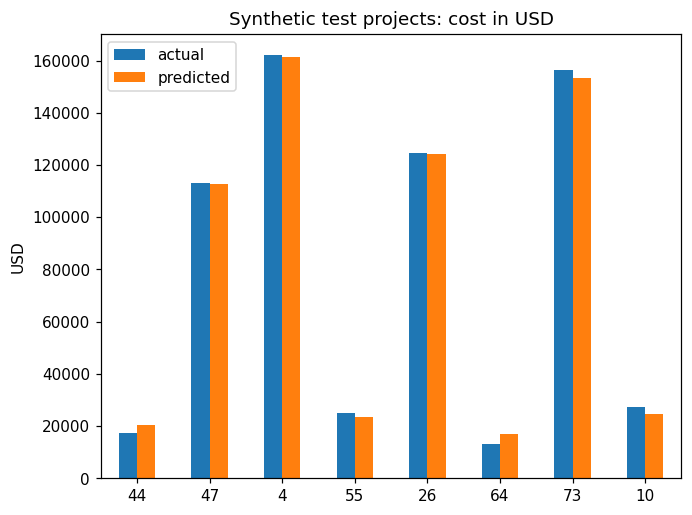

In [6]:
comparison = pd.DataFrame({"actual": y_test, "predicted": predicted})
print(comparison.head().round(2).to_string(index=False))
comparison.head(8).plot.bar(title="Synthetic test projects: cost in USD", rot=0)
plt.ylabel("USD")
plt.tight_layout()
plt.savefig("results/evaluation.png")
new_package = pd.DataFrame({"planned_cost": [50000], "complexity": [3]})
estimate = model.predict(new_package)[0]
print(f"Example final cost estimate: {estimate:.2f} USD")

## What I need to explain / Что нужно уметь объяснить

1. What each CSV column means.
2. Which information is known before prediction.
3. What `fit` and `predict` do.
4. Why we keep test data separate.
5. Whether this model beats its baseline, and what the errors mean.

These small synthetic test sets do not establish real-world accuracy. No real savings or company deployment are claimed. A real pilot needs approved historical records, forward-time validation and an engineer/planner responsible for decisions.
